# Project 3, Part A: Exploring the Power of Flow Models — Student Notebook

Use the current Part A assignment webpage for equations and deliverables.
Complete the student functions, run the provided display cells, and present your results
on your project webpage. This notebook follows the same three sections:

1. Visualizing Training and Sampling
2. Conditional Generation and Guidance
3. Creative Applications

## Start here
1. Select a **GPU**: Colab **Runtime → Change runtime type**, or Kaggle **Settings → Accelerator**. Enable Internet on Kaggle.
2. Run the **Setup** cell below. Everything needed is included or downloaded automatically.
3. Complete the exercises below and run their cells.

**No ZIP upload, Google Drive mount, helper-file edits, or cache configuration is needed.**
Use a fresh runtime when switching between Part A and Part B. Downloads are automatically
reused within the session. Save your notebook with outputs before disconnecting.

In [1]:
#@title Setup (run once)
# Supplied support code and images are embedded: no separate files are needed.
import os, sys, time, io, base64, zipfile, hashlib
from pathlib import Path
_cs180_started = time.perf_counter()
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = Path('/kaggle/working').is_dir()
PART = 'parta'
_work = Path('/content/cs180-hw3') if IN_COLAB else (Path('/kaggle/working') if IN_KAGGLE else Path.cwd())
_work.mkdir(parents=True,exist_ok=True)
_support = base64.b64decode('...')
assert hashlib.sha256(_support).hexdigest() == '7aad9f12cc6796cc2a79cab2a3beb9b10adb027dffc9ff7218302e0ccb480a6f', 'Damaged notebook support data'
with zipfile.ZipFile(io.BytesIO(_support)) as _archive:
    for _entry in _archive.infolist():
        _target=(_work/_entry.filename).resolve()
        if _work.resolve() not in _target.parents: raise ValueError('Unsafe embedded path')
    _archive.extractall(_work)
os.chdir(_work)
if str(_work) not in sys.path: sys.path.insert(0,str(_work))
from colab_setup import configure
configure(PART,install_dependencies=IN_COLAB or IN_KAGGLE)
print('Setup complete. Continue with the notebook below.')

Installing required packages: transformers==4.51.3, huggingface-hub==0.36.2
GPU: Tesla T4 VRAM GiB: 14.6
PyTorch: 2.11.0+cu130 torchvision: 0.26.0+cu130
Local cache: /content/cs180-hw3/.cache
Part A precision: float32 (text encoder and image model).
Setup complete. Continue with the notebook below.


In [2]:
import os, json, time, math
from pathlib import Path
from uuid import uuid4
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from torchvision.transforms.functional import gaussian_blur
from flow_model import FlowModel, preprocess, to_pil, MODEL_ID, MODEL_REVISION, TEXT_REVISION

torch.set_num_threads(4)
ROOT = Path.cwd()
GROUP = os.environ.get("FLOW_GROUP", "all")
if GROUP not in ("all", "core", "editing", "illusions"):
    raise ValueError("FLOW_GROUP must be all, core, editing, or illusions.")
# A new folder for this run keeps earlier results available.
RUN_NAME = time.strftime("%Y%m%d-%H%M%S") + "-" + uuid4().hex[:6]
OUT = ROOT / "results" / "parta_updated" / RUN_NAME
OUT.mkdir(parents=True, exist_ok=False)
SEED, H, W = 180, 0.02, 7
torch.manual_seed(SEED)
_model_key = (MODEL_REVISION, TEXT_REVISION, 'cuda:0', 'float32')
if globals().get('_loaded_model_key') != _model_key or 'model' not in globals():
    model = FlowModel()
    _loaded_model_key = _model_key
else:
    print('Reusing the already-loaded PixNerd model in this kernel.')
predict_velocity = model.predict_velocity
device = model.device
condition = model.encode("a high quality photo")
null_condition = model.encode("")


def load_input(path):
    if not str(path).strip():
        raise ValueError("Set the image path to a file you uploaded or saved in this runtime.")
    path = Path(path).expanduser()
    if not path.is_file():
        raise FileNotFoundError(f"Image not found: {path}. Check the path in the file browser.")
    return preprocess(path).to(device)


def noise(seed):
    return torch.randn((1, 3, 512, 512), generator=torch.Generator().manual_seed(seed)).to(device)


def panel(name, images, columns=4, title=None):
    items = list(images.items())
    fig, axs = plt.subplots(math.ceil(len(items) / columns), columns,
                            figsize=(4 * columns, 4 * math.ceil(len(items) / columns)),
                            squeeze=False, layout="constrained")
    if title is not None:
        fig.suptitle(title, wrap=True)
    for ax in axs.flat:
        ax.axis("off")
    for ax, (label, value) in zip(axs.flat, items):
        ax.imshow(to_pil(value))
        ax.set_title(label, fontsize=9, wrap=True)
    fig.savefig(OUT / (name + ".png"), dpi=110)
    plt.show()
    plt.close(fig)


def save(name, x):
    to_pil(x).save(OUT / (name + ".png"))


def guided(x, t, c=condition, w=W):
    return cfg_velocity(x, t, c, w, predict_velocity, null_condition)


metrics = {"group": GROUP, "seed": SEED, "step_size": H, "cfg_w": W,
           "model": MODEL_ID, "revision": MODEL_REVISION, "text_revision": TEXT_REVISION,
           "gpu": torch.cuda.get_device_name(0), "visible_devices": os.environ.get("CUDA_VISIBLE_DEVICES"),
           "torch": torch.__version__}
print("Results folder:", OUT)
print(metrics)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.ckpt:   0%|          | 0.00/4.70G [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/622M [00:00<?, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Results folder: /content/cs180-hw3/results/parta_updated/20261015-211356-9f8481
{'group': 'all', 'seed': 180, 'step_size': 0.02, 'cfg_w': 7, 'model': 'MCG-NJU/PixNerd-XXL-P16-T2I', 'revision': '9fa8836b553976b88a3b27649ed1628499e02bf9', 'text_revision': '70d244cc86ccca08cf5af4e1e306ecf908b1ad5e', 'gpu': 'Tesla T4', 'visible_devices': None, 'torch': '2.11.0+cu130'}


### Functions to implement

Run the cell below to define the function stubs. Fill in each function as you reach its
section, then rerun this cell after editing it. Follow the equations on the Part A webpage.
Image loading, text encoding, model evaluation, rotation, and low-pass filtering are provided.
The velocity-visualization exercise has its own student function in Section 1.4.

In [4]:
# STUDENT IMPLEMENTATION: complete each function in its corresponding section.

def interpolate(image, noise, t):
    return (1 - t) * noise + t * image


def one_step_denoise(x, t, condition, predict_velocity):
    raise NotImplementedError("Implement one_step_denoise in Section 1.3.")


@torch.inference_mode()
def euler_sample(x_start, t_start, step_size, velocity):
    raise NotImplementedError("Implement euler_sample in Section 1.5.")


def cfg_velocity(x, t, condition, w, predict_velocity, null_condition=''):
    raise NotImplementedError("Implement cfg_velocity in Section 2.1.")


def edit(image, noise, t_start, condition, predict_velocity, w=7, step_size=0.02):
    raise NotImplementedError("Implement edit in Section 3.1.")


# PROVIDED: rotate by 180 degrees, keeping the batch and RGB axes unchanged.
def rotate180(x):
    return torch.flip(x, (-2, -1))


def visual_anagrams(noise, condition_a, condition_b, predict_velocity, w=7, step_size=0.02):
    raise NotImplementedError("Implement visual_anagrams in Section 3.3.")


# PROVIDED: at 512 x 512, this uses kernel size 265 and sigma 16.
def lowpass(x, sigma=16.0):
    kernel = 2 * round(16.5 * x.shape[-1] / 64) + 1
    return gaussian_blur(x, [kernel, kernel], [sigma, sigma])


def make_hybrids(noise, condition_a, condition_b, predict_velocity, w=7, step_size=0.02):
    raise NotImplementedError("Implement make_hybrids in Section 3.4.")

# 1. Visualizing Training and Sampling

Use the linear flow-matching convention from the webpage:
$x_t=(1-t)\epsilon+t x_1$, where $\epsilon\sim\mathcal{N}(0,I)$.
**Time 0 is noise; time 1 is a clean image.** The path velocity target is $x_1-\epsilon$.
We use the pretrained model; no model training is required in Part A.

### Choose your image for Sections 1.1–1.5

Use **one image of your own, not the provided image of the Campanile**, throughout these five exercises.
Upload or add your image to the runtime, then set `YOUR_IMAGE_PATH` below to its path.
In Colab, upload through the Files sidebar and copy the uploaded file's path.
In Kaggle, add the image as an input and copy its path from the file browser.

The supplied preprocessing center-crops and resizes the image to $512\times512$ and
normalizes RGB to $[-1,1]$. The Campanile will be loaded separately for Sections 3.1–3.2.

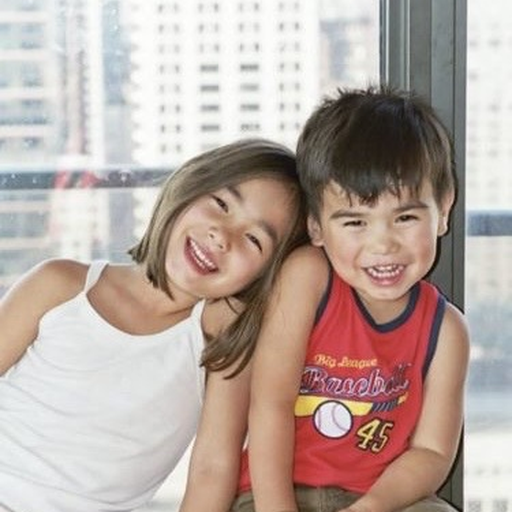

In [5]:
YOUR_IMAGE_PATH = "/content/0d7370db-39cf-4a88-a2c2-0f684ce587c4.jpg"  # Set this to the path of your own uploaded image.
image = load_input(YOUR_IMAGE_PATH)
metrics["own_image_path"] = str(Path(YOUR_IMAGE_PATH).expanduser().resolve())
display(to_pil(image))

## 1.1 Constructing Noisy Training Inputs

Implement `interpolate(image, noise, t)` using $x_t=(1-t)\epsilon+t x_1$.
Sample one noise tensor and reuse it at $t=0.25,0.50,0.75$.
Show your original image and the three noisy inputs, labeled by time.

**Hints:** Check both endpoints. Keep `image`, `epsilon`, and `noisy` for Sections 1.2–1.5;
the original image/noise pair is needed to compute the ground-truth velocity in Section 1.4.

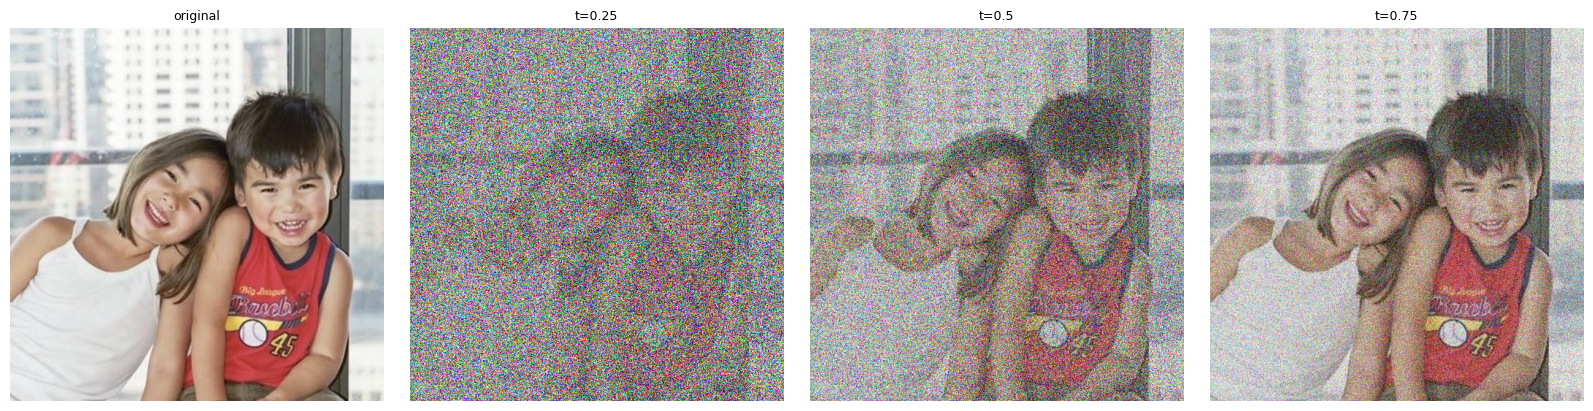

In [6]:
epsilon = noise(SEED)
noisy = {t: interpolate(image, epsilon, t) for t in [.25,.50,.75]}
assert torch.equal(interpolate(image,epsilon,0),epsilon)
assert torch.equal(interpolate(image,epsilon,1),image)
if GROUP in ("all","core"):
    torch.save({"image": image.cpu(), "epsilon": epsilon.cpu(),
                "noisy": {t: x.cpu() for t, x in noisy.items()}}, OUT / "noisy_inputs.pt")
    panel("training_inputs", {"original": image, **{f"t={t}":x for t,x in noisy.items()}})

## 1.2 Classical Denoising

For each saved input, restore the clean-image amplitude with x/t, then apply a Gaussian filter.
Try different blur strengths and show your best result beside each noisy input.
The provided cell sweeps sigma=1,2,4,8,16 and selects lowest mean squared error to the known clean image;
this is a baseline comparison, not a learned model or a guarantee of perceptual quality.

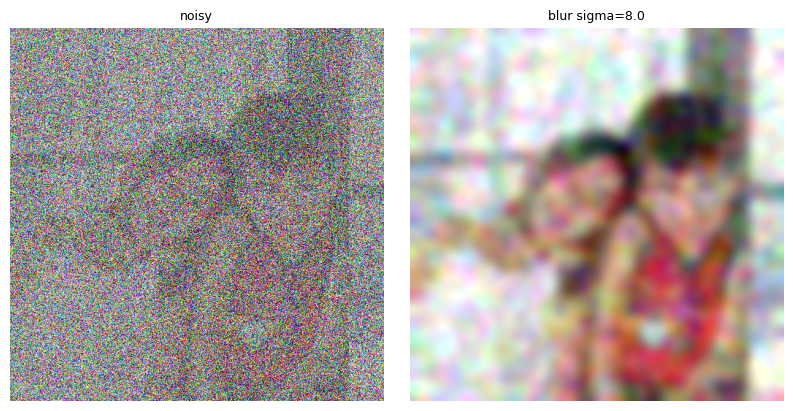

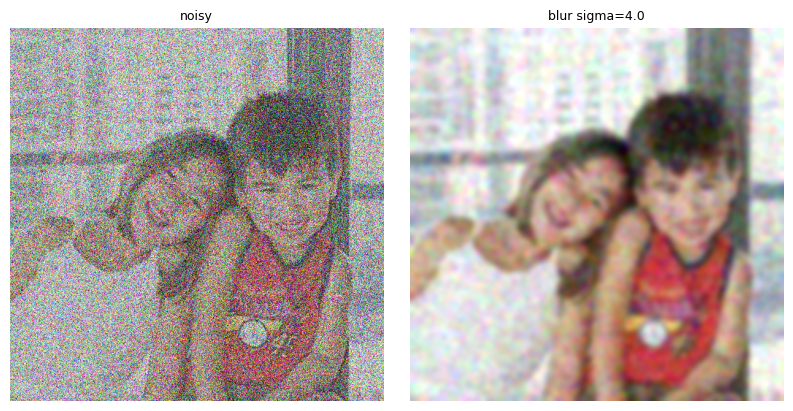

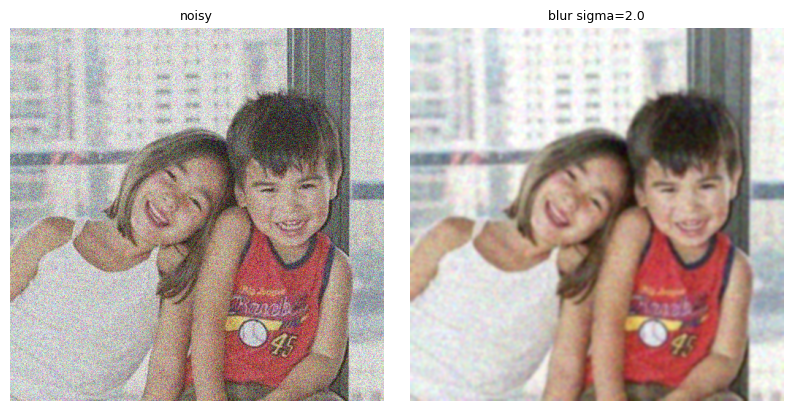

In [7]:
if GROUP in ("all","core"):
    blurred = {}
    for t,x in noisy.items():
        candidates = {s: gaussian_blur(x/t, [int(6*s+1)]*2, [s,s]) for s in [1.,2.,4.,8.,16.]}
        sigma = min(candidates, key=lambda s: ((candidates[s]-image)**2).mean().item())
        blurred[t] = candidates[sigma]
        panel(f"blur_{t}", {"noisy":x,f"blur sigma={sigma}":blurred[t]}, columns=2)

## 1.3 One-Step Denoising

Implement `one_step_denoise`: x̂₁=xₜ+(1−t)vθ(xₜ,t,c).
Use exactly one prediction for each of the same three noisy tensors, with “a high quality photo”.
Display original, input, and estimate. Check velocity shape, dtype, and device.

In [ ]:
if GROUP in ("all","core"):
    v = predict_velocity(noisy[.5], .5, condition)
    assert v.shape == image.shape and v.dtype == image.dtype and v.device == image.device
    assert torch.isfinite(v).all()
    one_step = {t:one_step_denoise(x,t,condition,predict_velocity) for t,x in noisy.items()}
    for t,x in noisy.items():
        panel(f"one_step_{t}", {"original":image,"noisy":x,"one step":one_step[t]}, columns=3)

## 1.4 Visualizing Velocity

In Section 1.3, we added $(1-t)\hat v_t$ to the noisy image to estimate the clean image.
Here, visualize what the model adds and compare it with the update $x_1-x_t$
that would recover your original image.

Use the same image and saved noisy inputs at $t=0.25,0.50,0.75$, with
`"a high quality photo"`.

**Deliverables**
- Show the original image once.
- At each time, show the noisy input, predicted update $(1-t)\hat v_t$,
  ground-truth update $(1-t)v_{\mathrm{gt}}$, and an error heatmap, labeled by time.
  You may arrange the displays however you like.

**Implementation hints**
- Predict $\hat v_t=v_\theta(x_t,t,c)$. Using the saved noise, compute
  $v_{\mathrm{gt}}=x_1-\epsilon$, so $(1-t)v_{\mathrm{gt}}=x_1-x_t$.
- For the error map, use RMS across RGB **at each pixel**:
  $E_t=\sqrt{\operatorname{mean}_{\mathrm{RGB}}([(1-t)(\hat v_t-v_{\mathrm{gt}})]^2)}$.
  Square the channel differences, average over RGB, and take the square root before display scaling.
- Use one shared symmetric RGB scale for all updates, with zero at middle gray.
- Use `matplotlib.pyplot.imshow` with a linear scale for errors. Choose `vmin` and `vmax`
  that work for your image, keeping them the same at all three times.

Complete the calculation function below. The following cell supplies an example display.

In [ ]:
@torch.inference_mode()
def velocity_diagnostics(x_t, t, clean_image, epsilon, condition, predict_velocity):
    """Return predicted_update, ground_truth_update, and error_map.

    Both updates have shape (B, 3, H, W).
    The error map has shape (B, H, W): average only over RGB, keeping each pixel.
    Return raw values before display scaling or clipping.
    """
    # STUDENT IMPLEMENTATION: use the equations in Section 1.4.
    raise NotImplementedError("Compute the two updates and their per-pixel RGB RMS error.")

In [ ]:
# PROVIDED display helpers. Adjust the error limits or layout for your results.
ERROR_VMIN = 0.0
ERROR_VMAX = None  # None uses the maximum across all three maps; you may choose a smaller limit.


def signed_rgb(update, limit):
    # Map the shared signed range [-limit, limit] to RGB [0, 1].
    value = update.detach().float().cpu()[0].permute(1, 2, 0)
    return (0.5 + value / (2 * limit)).numpy()


if GROUP in ("all", "core"):
    velocity_results = {}
    for t in (0.25, 0.50, 0.75):
        predicted_update, target_update, error_map = velocity_diagnostics(
            noisy[t], t, image, epsilon, condition, predict_velocity)
        if predicted_update.shape != image.shape or target_update.shape != image.shape:
            raise ValueError("Each update should have the same shape as the input image.")
        if error_map.shape != (image.shape[0], *image.shape[-2:]):
            raise ValueError("The error map should have shape (B, H, W); average only over RGB.")
        velocity_results[t] = tuple(value.detach().float().cpu() for value in
                                    (predicted_update, target_update, error_map))

    signed_limit = max(1e-8, *(float(value.abs().max())
                             for predicted, target, _ in velocity_results.values()
                             for value in (predicted, target)))
    error_max = ERROR_VMAX
    if error_max is None:
        error_max = max(1e-8, *(float(error.max()) for _, _, error in velocity_results.values()))
    if error_max <= ERROR_VMIN:
        raise ValueError("Choose ERROR_VMAX greater than ERROR_VMIN.")

    print("Original image")
    display(to_pil(image))
    save("velocity_original", image)
    for t, (predicted_update, target_update, error_map) in velocity_results.items():
        fig, axes = plt.subplots(1, 4, figsize=(16, 4), layout="constrained")
        fig.suptitle(f"t = {t:.2f}")
        axes[0].imshow(to_pil(noisy[t]))
        axes[1].imshow(signed_rgb(predicted_update, signed_limit))
        axes[2].imshow(signed_rgb(target_update, signed_limit))
        axes[3].imshow(error_map[0].numpy(), vmin=ERROR_VMIN, vmax=error_max)
        for ax, title in zip(axes, ("Noisy image", r"Predicted $(1-t)\hat v$",
                                    r"Ground truth $(1-t)v_{\mathrm{gt}}$", "Error (RGB RMS)")):
            ax.set_title(title)
            ax.axis("off")
        fig.savefig(OUT / f"velocity_{t:.2f}.png", dpi=110)
        plt.show()
        plt.close(fig)

## 1.5 Iterative Denoising with Euler Sampling

Implement `euler_sample(x_start,t_start,step_size,velocity)`:
xₜ₊ₕ=xₜ+h·v(xₜ,t). Recompute velocity each step and shorten the final step to reach 1 exactly.
Return the final tensor and saved states. Denoise the saved t=0.50 input with h=0.02 (25 updates).
Show the initial state, every fifth update, and final result, labeled by time. Compare blur, one-step,
and iterative results on this same input.

In [ ]:
if GROUP in ("all","core"):
    calls=[]
    def constant_v(x,t):
        calls.append(t); return torch.ones_like(x)
    toy=torch.zeros(1,3,4,4,device=device)
    for start,step,expected in [(0,.02,50),(.5,.02,25),(.93,.02,4)]:
        calls.clear(); end,states=euler_sample(toy,start,step,constant_v)
        assert len(calls)==expected and states[-1][0]==1
        assert torch.allclose(end,torch.full_like(toy,1-start),atol=1e-6)
    iterative,trajectory=euler_sample(noisy[.5],.5,H,lambda x,t:predict_velocity(x,t,condition))
    panel("trajectory",{f"t={t:.2f}":x for t,x in trajectory},3)
    panel("comparison",{"original":image,"blur":blurred[.5],"one step":one_step[.5],"Euler":iterative})
    metrics["reconstruction_mse"]={k:float(((v-image)**2).mean()) for k,v in
        {"blur":blurred[.5],"one_step":one_step[.5],"euler":iterative}.items()}
    metrics["euler_checks"]="50 full steps, 25 half steps, shortened final step passed"

## 1.6 Generating Images from Noise

Generate five independent Gaussian initial states and integrate from 0 to 1 (50 Euler updates).
Use “a high quality photo”. Show all five results and record the seeds.

In [ ]:
if GROUP in ("all","core"):
    samples={}
    for i in range(5):
        x,_=euler_sample(noise(SEED+i),0,H,lambda x,t:predict_velocity(x,t,condition))
        samples[f"seed={SEED+i}"]=x; save(f"conditional_{i}",x)
    panel("conditional_samples",samples)

# 2. Conditional Generation and Guidance

Section 1 used a fixed text prompt. Here, implement classifier-free guidance to strengthen
the prompt's effect and compare the resulting samples.

## 2.1 Classifier-Free Guidance

Implement v_cfg=v_c+w(v_c−v_u), with empty-string null condition.
Both branches must evaluate the same x and t. w=0 gives ordinary conditional prediction.
Generate five images at w=7 and h=0.02. Compare to Section 1.6 using the same initial noises.


In [ ]:
if GROUP in ("all","core"):
    x=noise(SEED)
    assert torch.equal(cfg_velocity(x,.5,condition,0,predict_velocity,null_condition),predict_velocity(x,.5,condition))
    cfg_samples={}
    for i in range(5):
        x,_=euler_sample(noise(SEED+i),0,H,guided)
        cfg_samples[f"seed={SEED+i}, w={W}"]=x; save(f"cfg_{i}",x)
    panel("cfg_samples",cfg_samples)
    metrics["cfg_zero_check"]=True

# 3. Creative Applications

Use Euler step size `h=0.02`, CFG weight `w=7`, and the empty-string prompt for the
unconditional prediction throughout this section.

## 3.1 Image-to-Image Editing

Implement `edit`: construct $(1-t_{\mathrm{start}})\epsilon+t_{\mathrm{start}}x_1$
and integrate from the starting time to 1 with CFG.
Use `"a high quality photo"` and the **seven** starting times
**0.02, 0.04, 0.06, 0.10, 0.14, 0.25, 0.50**.

Show the original and all seven edits for the **Campanile and two images of your own**.
The Campanile is included in setup. Set the two image paths below; you may reuse your image
from Section 1.1 as one of them. These inputs will also be used in Section 3.2.

In [ ]:
# The same seven times are used throughout Sections 3.1 and 3.2.
STARTS = [0.02, 0.04, 0.06, 0.10, 0.14, 0.25, 0.50]
TEST_IMAGE_PATHS = {
    "my_image_1": YOUR_IMAGE_PATH,
    "my_image_2": "",  # Add the path of a second image of your own.
}

if GROUP in ("all", "editing"):
    # Load Campanile separately; `image` remains your Section 1 image.
    campanile = load_input(ROOT / "assets/campanile.jpg")
    edit_inputs = {"campanile": campanile,
                   **{name: load_input(path) for name, path in TEST_IMAGE_PATHS.items()}}
    for name, y in edit_inputs.items():
        panel("edit_" + name, {"original": y, **{
            f"t={t:.2f}": edit(y, noise(SEED), t, condition, predict_velocity, w=W, step_size=H)
            for t in STARTS}})
        print("Edited", name, flush=True)

### Editing Hand-Drawn and Web Images

Repeat the same procedure and **seven starting times** for **one image from the web and
two of your own drawings**. Download or draw the images, upload/add them to the runtime,
and set their paths below. The preprocessing helper center-crops to a square and resizes
to 512×512, so keep your drawings centered.

In [ ]:
WEB_IMAGE_PATH = ""  # Path of an image you downloaded from the web.
DRAWING_PATHS = {
    "drawing_1": "",  # Path of your first drawing.
    "drawing_2": "",  # Path of your second drawing.
}

if GROUP in ("all", "editing"):
    creative_inputs = {"web_image": load_input(WEB_IMAGE_PATH),
                       **{name: load_input(path) for name, path in DRAWING_PATHS.items()}}
    for name, y in creative_inputs.items():
        panel("edit_" + name, {"original": y, **{
            f"t={t:.2f}": edit(y, noise(SEED), t, condition, predict_velocity, w=W, step_size=H)
            for t in STARTS}})
        print("Edited", name, flush=True)

## 3.2 Text-Guided Image Editing

Reuse the Campanile and two personal images from Section 3.1. For each image, choose a prompt
describing your desired edit and replace the generic photo prompt with its embedding.
Use the same **seven starting times: 0.02, 0.04, 0.06, 0.10, 0.14, 0.25, 0.50**.
Show the original and all edits, with the chosen prompt and times.

Larger starting times preserve more of the original image. Smaller starting times add more
noise and give the model more room to change the image according to the prompt.

In [ ]:
EDIT_PROMPTS = {
    "campanile": "",  # Choose a prompt, e.g. "a photograph of a rocket on a launch pad".
    "my_image_1": "",  # Describe your desired edit for this image.
    "my_image_2": "",  # Describe your desired edit for this image.
}

if GROUP in ("all", "editing"):
    if set(EDIT_PROMPTS) != set(edit_inputs):
        raise ValueError("Provide one editing prompt for each image from Section 3.1.")
    if any(not prompt.strip() for prompt in EDIT_PROMPTS.values()):
        raise ValueError("Fill in all three EDIT_PROMPTS before running this cell.")
    for name, prompt in EDIT_PROMPTS.items():
        c = model.encode(prompt)
        y = edit_inputs[name]
        panel("text_edit_" + name, {"original": y, **{
            f"t={t:.2f}": edit(y, noise(SEED), t, c, predict_velocity, w=W, step_size=H)
            for t in STARTS}}, title=f'{name}: "{prompt}"')
        print("Text edited", name, flush=True)

## 3.3 Visual Anagrams

Let F rotate an image 180 degrees (flip both spatial axes, not just vertical reflection).
Average v_cfg(x,t,c_a) and F(v_cfg(F(x),t,c_b)), and integrate using the same Euler sampler.
Choose two prompt pairs and generate two illusions. Show each upright and rotated with both prompts. Several prompt/seed attempts
may be needed: a successful numerical run does not imply both subjects are recognizable.

In [ ]:
if GROUP in ("all","illusions"):
    assert torch.equal(rotate180(rotate180(image)),image)
    # Example prompt pairs; edit these to choose your two illusions.
    pairs=[("an oil painting of an old man","an oil painting of people around a campfire"),
           ("a lithograph of a snowy mountain village","a lithograph of a horse")]
    for i,(a,b) in enumerate(pairs):
        x=visual_anagrams(noise(SEED+i),model.encode(a),model.encode(b),predict_velocity,w=W,step_size=H)
        save(f"anagram_{i}",x); panel(f"anagram_views_{i}",{a:x,b:rotate180(x)},2)
    metrics["rotation_involution_check"]=True

## 3.4 Hybrid Images

Implement `make_hybrids` using `lowpass(v_a) + v_b - lowpass(v_b)` in each Euler update.
Prompt `a` determines the distant structure; prompt `b` determines the close-up detail.
Use the same image and time for both CFG predictions. The provided low-pass helper uses
Gaussian blur with sigma 16 and kernel size 265 at 512×512.

Choose two prompt pairs and generate **two hybrid images**. Show each at full and reduced size,
labeling both prompts. The example pairs below match the subjects and viewing directions
shown on the webpage; you can choose other pairs. Several attempts may be needed.

In [ ]:
if GROUP in ("all", "illusions"):
    # (distant / low-frequency prompt, close / high-frequency prompt)
    pairs = [("a lithograph of a skull", "a lithograph of a waterfall"),
             ("a lithograph of a cat", "a lithograph of a forest")]
    for i, (distant_prompt, close_prompt) in enumerate(pairs):
        x = make_hybrids(noise(SEED+i), model.encode(distant_prompt), model.encode(close_prompt),
                         predict_velocity, w=W, step_size=H)
        save(f"hybrid_{i}", x)
        print("Close:", close_prompt)
        display(to_pil(x))
        print("Distant:", distant_prompt)
        display(to_pil(x).resize((64, 64), Image.Resampling.LANCZOS))
    metrics["hybrid_lowpass_sigma"] = 16

# Bells & Whistles

**Required for CS280A students:**
- Create visual anagrams using two additional transformations from the
  [Visual Anagrams paper](https://arxiv.org/abs/2311.17919).
- Design a course logo, for example by applying text-guided image editing to a drawing
  or the UCB logo.

**Optional for everyone:** Explore your own ideas. Add cells below for your experiments
and include the results on your project webpage.

In [ ]:
# Add your Bells & Whistles experiments here.

### Save your results

Inspect your saved images as well as the numerical checks. The cell below saves the run's
settings and metrics alongside its figures. Save this notebook with its outputs before
disconnecting from the runtime.

In [ ]:
metrics["peak_memory_gib"]=torch.cuda.max_memory_allocated()/2**30
(OUT/"metrics.json").write_text(json.dumps(metrics,indent=2))
print(json.dumps(metrics,indent=2))

# Deliverable Checklist

- Include every section's required results and explanations on your project webpage.
- Submit your website PDF and code to the corresponding Gradescope assignments.
- The Google Form is not required for Part A; complete it after both parts are finished.
- CS280A students should also include both required Bells & Whistles tasks.

The project is due October 20, 2026. Follow the assignment webpage for complete submission instructions.